# Cvičenie 7

Detekcia hrán a Houghova transformácia

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import ipywidgets as widgets
import skimage as sk
from scipy.signal import convolve2d
import scipy

# Úloha 1

Applikujte Robertsov, Prewittov a Sobelov operátor podľa prednášky.
Upravte percentil tak, aby boli zobrazene iba hrany.

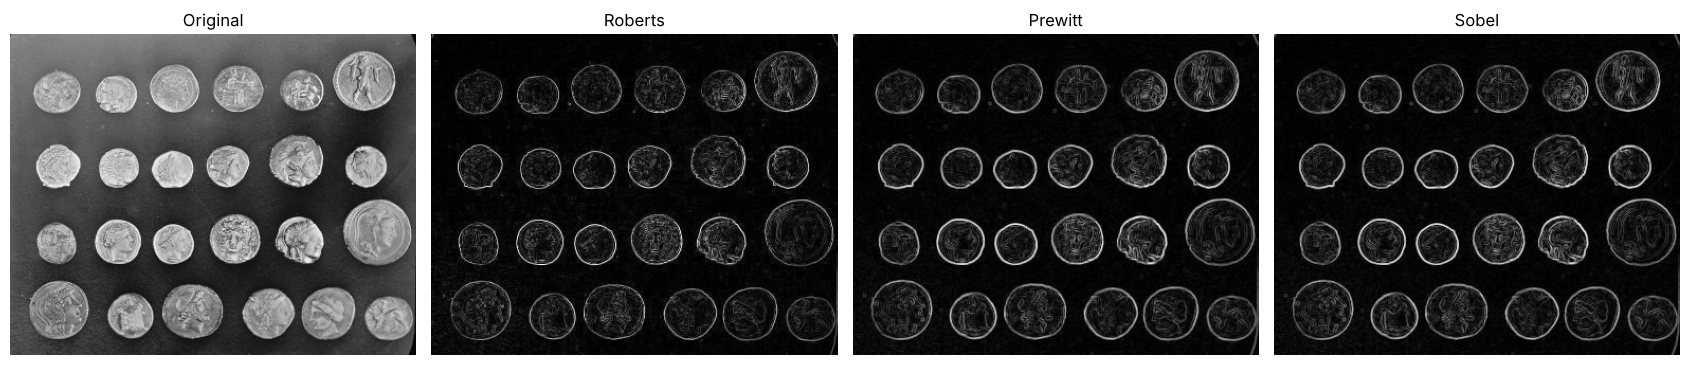

In [2]:
image = sk.data.coins()
image = sk.util.img_as_float(image)

roberts_x = np.array([[1, 0],
                      [0, -1]])
roberts_y = np.array([[0, 1],
                      [-1, 0]])

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])
prewitt_y = prewitt_x.T

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = sobel_x.T

roberts_gx = convolve2d(image, roberts_x, mode="same", boundary="symm")
roberts_gy = convolve2d(image, roberts_y, mode="same", boundary="symm")
roberts_hrany = np.sqrt(roberts_gx**2+roberts_gy**2)

prewitt_gx = convolve2d(image, prewitt_x, mode="same", boundary="symm")
prewitt_gy = convolve2d(image, prewitt_y, mode="same", boundary="symm")
prewitt_hrany = np.sqrt(prewitt_gx**2 + prewitt_gy**2)

sobel_gx = convolve2d(image, sobel_x, mode="same", boundary="symm")
sobel_gy = convolve2d(image, sobel_y, mode="same", boundary="symm")
sobel_hrany = np.sqrt(sobel_gx**2 + sobel_gy**2)

fig, ax = plt.subplots(1, 4, figsize=(17, 5))
for a, obr, nazov in zip(ax, [image, roberts_hrany, prewitt_hrany, sobel_hrany],
                         ["Original", "Roberts", "Prewitt", "Sobel"]):
    a.imshow(obr, cmap="gray")
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()

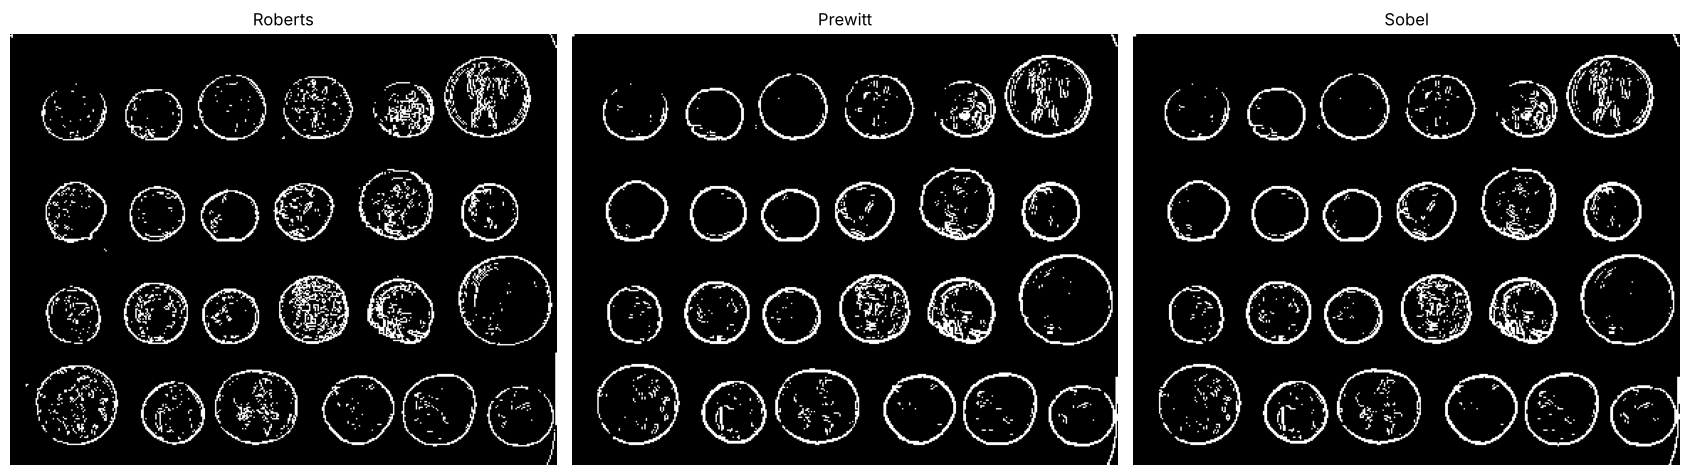

Roberts:0.21  Prewitt:0.64, Sobel:0.86


In [3]:
P = 92
T_r = np.percentile(roberts_hrany, P)
T_p = np.percentile(prewitt_hrany, P)
T_s = np.percentile(sobel_hrany, P)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, obr, nazov in zip(ax, [ roberts_hrany > T_r,
                               prewitt_hrany > T_p,
                               sobel_hrany > T_s],
                         [ "Roberts", "Prewitt", "Sobel"]):
    a.imshow(obr, cmap="gray")
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()
print(f"Roberts:{T_r:.2f}  Prewitt:{T_p:.2f}, Sobel:{T_s:.2f}")

# Úloha 2

Podobne pre metódu druhej derivácie.
Teda najskor applikácia Laplaceovho operátora, potom označenie prechodov cez nulu.

Funkciu prechody nulou nájdete napr. v prednáške.

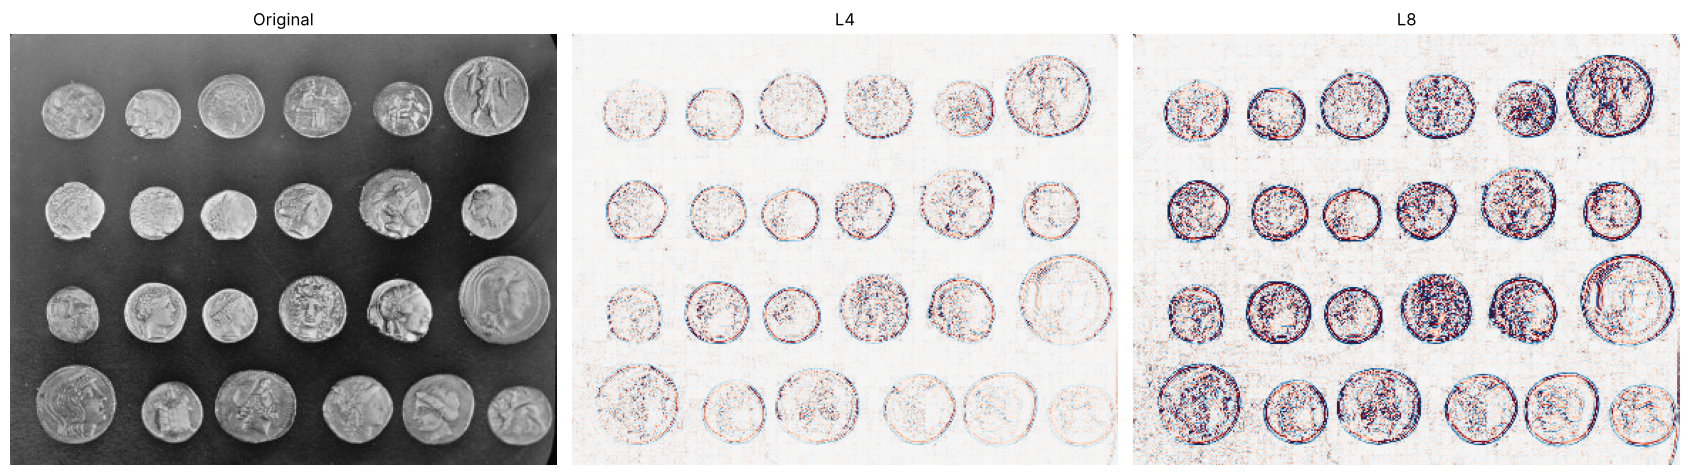

In [4]:
laplace_4 = np.array([[0, 1, 0],
                      [1, -4, 1],
                      [0, 1, 0]])
laplace_8 = np.array([[1, 1, 1],
                      [1, -8, 1],
                      [1, 1, 1]])

laplace_4_image = convolve2d(image, laplace_4, mode="same", boundary="symm")
laplace_8_image = convolve2d(image, laplace_8, mode="same", boundary="symm")

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, obr, nazov in zip(ax, [image, laplace_4_image, laplace_8_image],
                         [ "Original", "L4", "L8"]):
    if obr is image:
        a.imshow(obr, cmap="gray", vmin=0, vmax=1)
        a.set_title(nazov)
        a.axis("off")
        continue
    a.imshow(obr, cmap="RdBu", vmin=-1, vmax=1)
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()

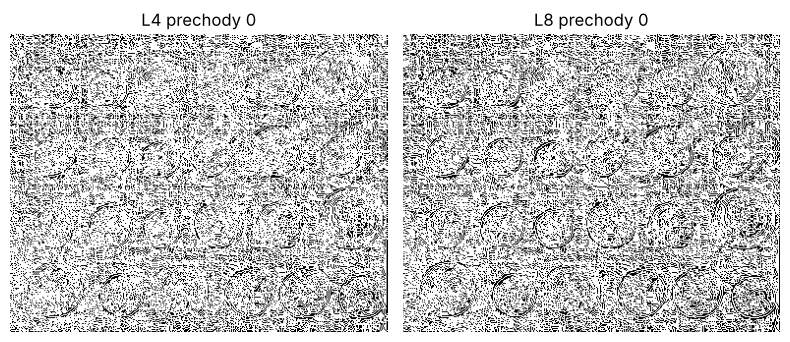

In [5]:
def prechody_nulou(L):
    # pixel je hrana, ak sa znamienko Laplaceovho obrazu zmení
    # medzi ním a jeho pravým alebo dolným susedom
    znamienko = L > 0
    hrany = np.zeros(L.shape, dtype=bool)
    hrany[:, :-1] |= znamienko[:, :-1] != znamienko[:, 1:]   # vodorovne
    hrany[:-1, :] |= znamienko[:-1, :] != znamienko[1:, :]   # zvislo
    return hrany.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(8, 5))
for a, obr, nazov in zip(ax, [prechody_nulou(laplace_4_image), prechody_nulou(laplace_8_image)],
                         [ "L4 prechody 0", "L8 prechody 0"]):
    a.imshow(obr, cmap="gray", vmin=0, vmax=1)
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()

# Úloha 3
Laplacián Gaussiánu - najskor signál vyhladíme a až potom použijeme Laplacov operátor.

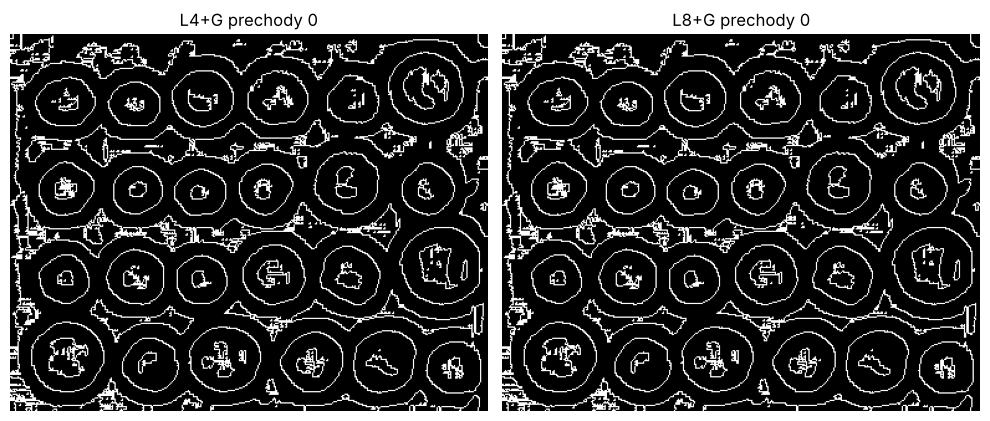

In [6]:
g1 = scipy.signal.windows.gaussian(21, std=5.0)
g1 /= g1.sum()
h_gauss = np.outer(g1, g1)                           # 21 x 21

gaussian = convolve2d(image, h_gauss, mode="same", boundary="symm")

laplace_4_gausianu = convolve2d(gaussian, laplace_4, mode="same", boundary="symm")
laplace_8_gausianu = convolve2d(gaussian, laplace_8, mode="same", boundary="symm")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, obr, nazov in zip(ax, [prechody_nulou(laplace_4_gausianu), prechody_nulou(laplace_8_gausianu)],
                         [ "L4+G prechody 0", "L8+G prechody 0"]):
    a.imshow(obr, cmap="gray", vmin=0, vmax=1)
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()

# Úloha 4

Cannyho detektor z knižnice skimage (scikit-image).
Porovnajte detekciu hrán s tou Sobelovou.

Čo znamenajú jednotlivé nastavenia?

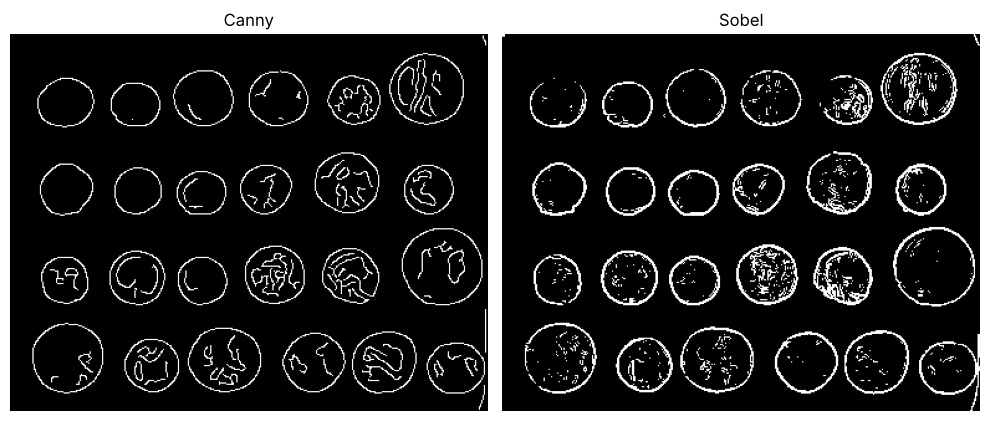

In [7]:
# sigma - smerodajna odchylka Gaussovho vyhladenia pred hladanim hran
# low_threshold / high_threshold - dolny a horny prah hysterezie
#   (pixel nad horným prahom je urcite hrana, pixel medzi prahmi je hrana len ak
#    sa dotyka silnej hrany, pod dolnym prahom sa zahodi)
canny_hrany = sk.feature.canny(image, sigma=2)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, obr, nazov in zip(ax, [canny_hrany, np.where(sobel_hrany > T_s, 1, 0)],
                         [ "Canny", "Sobel"]):
    a.imshow(obr, cmap="gray", vmin=0, vmax=1)
    a.set_title(nazov)
    a.axis("off")
plt.tight_layout()
plt.show()

# Úloha 5

Bloby

Pozrite dokumentáciu scikit-image a zistite pre ake nastavenie funkcie blob_log vráti správny počet mincí.

Pocet mincí: 24


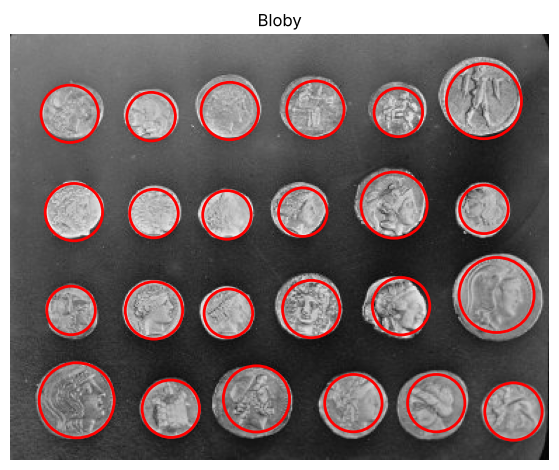

In [8]:
# min_sigma, max_sigma - rozsah hladanych velkosti blobov (polomer = sqrt(2)*sigma)
# num_sigma - pocet testovanych hodnot sigma, threshold - minimalna odozva detektora
deteg_blob = sk.feature.blob_log(image, min_sigma=10, max_sigma=30, num_sigma=10, threshold=0.1)
print("Pocet mincí:", len(deteg_blob))

fig, ax = plt.subplots()
ax.imshow(image, cmap="gray", vmin=0, vmax=1)
for y, x, sigma in deteg_blob:
    ax.add_patch(Circle((x, y), np.sqrt(2) * sigma, fill=False, edgecolor="red", linewidth=2))
ax.set_title("Bloby")
ax.axis("off")
plt.tight_layout()
plt.show()

# Úloha 6
Pomocou Houghovej transformácie označte priamky v obrázku sk.data.brick().

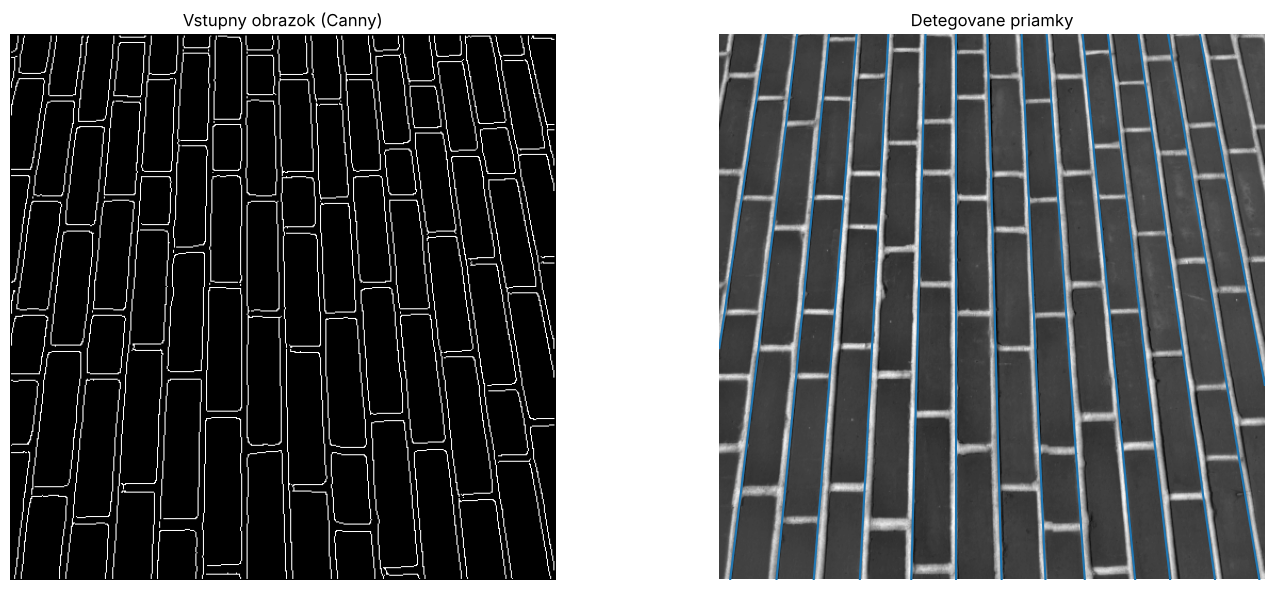

In [9]:
image_orig  = sk.data.brick()
image = sk.util.img_as_float(image_orig)
image = sk.feature.canny(image, sigma=2)

tested_angles = np.linspace(-np.pi / 2, np.pi / 2, 360, endpoint=False)
accum, theta, d = sk.transform.hough_line(image, theta=tested_angles)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes.ravel()

ax[0].imshow(image, cmap="gray")
ax[0].set_title('Vstupny obrazok (Canny)')
ax[0].set_axis_off()

ax[1].imshow(image_orig, cmap="gray")
ax[1].set_ylim((image.shape[0], 0))
ax[1].set_axis_off()
ax[1].set_title('Detegovane priamky')

for _, angle, dist in zip(*sk.transform.hough_line_peaks(accum, theta, d, num_peaks=20, threshold=0.5 * accum.max())):
    (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
    ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

plt.tight_layout()
plt.show()